# 더위회피 곤란구간 — 발표자료 그림 생성 노트북

`최종_곤란구간_유형AB.ipynb`가 산출한 **`A_곤란구간_확정_v2.geojson`** 하나만 있으면
발표자료(PPT)에 들어간 그림 6종을 전부 다시 만들 수 있도록 흩어져 있던 스크립트를 한 파일로 합친 것이다.

| # | 그림 | 무엇을 보여주는가 | 출력 파일 |
|---|---|---|---|
| 1 | 링크별 열노출 지도 | 격자 열지수를 도로 링크로 옮긴 `heat_norm`의 지구별 분포 | `heat_norm_map_1700x290.png` |
| 2 | HH 클러스터 지도 | 열노출 HH(빨강) · 회피경로 사용 HH(파랑) · 겹침(보라) | `hh_map_46x10cm.png`, `hh_map_46x7cm.png` |
| 3 | 회피경로 이용현황 지도 | 회피경로가 실제로 지나간 링크와 겹침 강도 | `avoid_route_usage_1200x450.png` |
| 4 | 우회율 vs 열저감률 | 지구별 우회 부담과 그 대가로 얻는 열노출 저감 | `detour_vs_heatreduce_860x510.png`, `..._860x440.png` |
| 5 | α 민감도 곡선 | 비용함수 α를 바꿀 때 우회율·열저감률의 변화 | `alpha_sensitivity_860x310.png` |
| 6 | 유형 A/B 확정 표 | 지구별 유형A·유형B·복합형 개수 | `type_ab_table.png` |

마지막 **7절(검증)** 에서는 그림에 찍힌 숫자를 원본 GeoJSON에서 다시 세어 대조한다.

> **픽셀 크기 주의** — 그림 대부분은 PPT 슬라이드에 맞춰 가로·세로 픽셀을 고정해 둔 것이다.
> `bbox_inches="tight"` 를 쓰면 여백이 잘려 픽셀 크기가 달라지므로 **저장 시 절대 사용하지 않는다.**

## 0. 공통 설정

In [1]:
import os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import geopandas as gpd
import networkx as nx
import matplotlib
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from matplotlib.cm import ScalarMappable
from matplotlib.colors import Normalize
from shapely.geometry import Point
from shapely.strtree import STRtree

warnings.filterwarnings("ignore")
pd.set_option("display.width", 200)

# ── 경로 ──────────────────────────────────────────────
BASE    = Path(os.environ.get("GONRAN_BASE", ".."))          # 전달 폴더 최상위
DATA    = Path(os.environ.get("GONRAN_DATA", BASE / "03_출력" / "A_곤란구간_확정_v2.geojson"))
OD_FILE = Path(os.environ.get("GONRAN_OD",   BASE / "02_입력데이터" / "od_pairs_주요경로.csv"))
FIGDIR  = Path(os.environ.get("GONRAN_FIGDIR", BASE / "04_그림"))
OUTDIR  = Path(os.environ.get("GONRAN_OUTDIR", BASE / "03_출력"))
FIGDIR.mkdir(parents=True, exist_ok=True); OUTDIR.mkdir(parents=True, exist_ok=True)

# ── 공통 상수 ──────────────────────────────────────────
ZONES = ["분당", "판교", "왕숙", "창릉"]     # 그림의 패널 순서(발표자료와 동일)
ALPHA = 2.5                                  # cost = length x (1 + (alpha-1) x heat_norm)

# ── 한글 폰트 ─────────────────────────────────────────
# 발표자료는 본고딕(Noto Sans CJK KR)으로 제작됨. Windows에서는 맑은 고딕도 사용 가능.
for _f in ["Noto Sans CJK KR", "Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK JP"]:
    try:
        matplotlib.font_manager.findfont(_f, fallback_to_default=False)
        plt.rcParams["font.family"] = _f
        break
    except Exception:
        continue
plt.rcParams["axes.unicode_minus"] = False
print("폰트:", plt.rcParams["font.family"][0])

def save(fig, name, dpi):
    # 픽셀 크기를 고정해야 하므로 bbox_inches는 쓰지 않는다
    p = FIGDIR / name
    fig.savefig(p, dpi=dpi)
    from PIL import Image
    print(f"[저장] {name}  {Image.open(p).size[0]}x{Image.open(p).size[1]}px")

폰트: Noto Sans CJK JP


In [2]:
E = gpd.read_file(DATA)
print(f"{len(E):,}개 링크 | CRS {E.crs}")
print(E.groupby("zone").agg(링크수=("length", "size"),
                            연장km=("length", lambda s: round(s.sum()/1000, 1))).loc[ZONES].to_string())
print()
print("주요 컬럼:", [c for c in E.columns if c not in ("geometry",)][:20], "...")

4,762개 링크 | CRS EPSG:5179
       링크수   연장km
zone             
분당    2022  180.2
판교    1402   92.7
왕숙     737   66.0
창릉     601   55.5

주요 컬럼: ['edge_idx', 'zone', 'node_u', 'node_v', 'length', 'src', 'choice_full', 'form_pct_full', 'demand', 'dem_pct', '형태동선', '수요동선', '주요동선', '핵심동선', 'is_main', 'is_core', 'corr_id', 'heat', 'heat_norm', '_cx'] ...


---

## 1. 링크별 열노출 지도 (`heat_norm`)

30m 격자 열지수를 도로 링크에 옮긴 뒤 **지구 내 순위(0~1)** 로 정규화한 값이다. 지구마다 도시 규모와
열환경 수준이 달라 절대값을 그대로 비교하면 큰 지구가 항상 뜨겁게 보이므로, 지구 내부의 상대적 위치를 본다.

출력 픽셀: **1700 × 290** (슬라이드 상단 가로 배너용)

[저장] heat_norm_map_1700x290.png  1700x290px


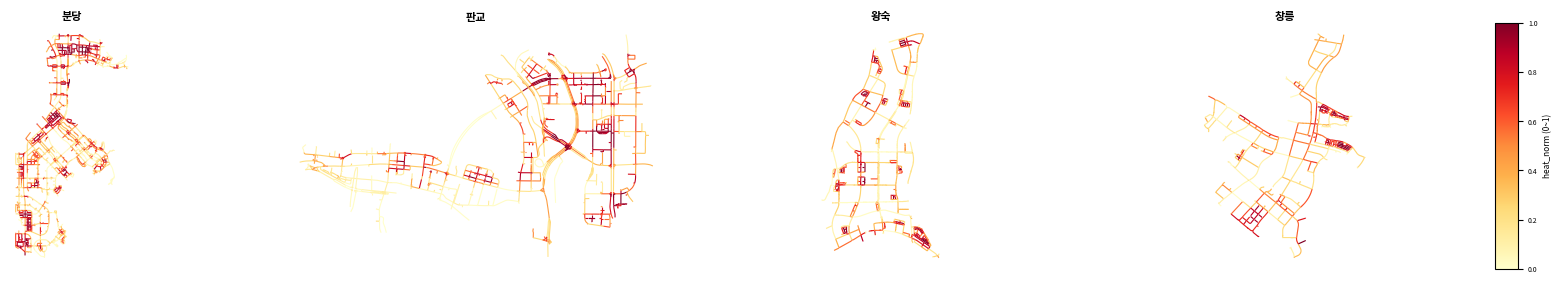

In [3]:
W_PX, H_PX, DPI = 1700, 290, 100
CMAP, VMIN, VMAX = "YlOrRd", 0, 1

fig = plt.figure(figsize=(W_PX/DPI, H_PX/DPI), dpi=DPI)
gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.06], wspace=0.05)
axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
cax = fig.add_subplot(gs[0, 4])

for ax, zone in zip(axes, ZONES):
    sub = E[E["zone"] == zone]
    sub.plot(ax=ax, column="heat_norm", cmap=CMAP, vmin=VMIN, vmax=VMAX, linewidth=0.8)
    ax.set_title(zone, fontsize=8, fontweight="bold", pad=2)
    ax.set_axis_off()

sm = ScalarMappable(norm=Normalize(vmin=VMIN, vmax=VMAX), cmap=CMAP); sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("heat_norm (0~1)", fontsize=6); cbar.ax.tick_params(labelsize=5)

fig.subplots_adjust(left=0.005, right=0.97, top=0.86, bottom=0.01)
save(fig, "heat_norm_map_1700x290.png", DPI)
plt.show()

---

## 2. HH 클러스터 지도 — 열노출 HH vs 회피경로 사용 HH

Local Moran's I(LISA)로 **주변과 함께 높은 값을 이루는 구간(High-High)** 을 지구별로 검정하고,
FDR 보정을 통과한 링크만 표시한다.

- **빨강** 열노출만 HH — 뜨겁지만 회피경로가 몰리지는 않는 구간
- **파랑** 회피경로 사용만 HH — 사람들이 몰려 우회하는 통로
- **보라** 둘 다 HH — 뜨거우면서 회피경로까지 몰리는 구간

출력: PPT 삽입 기준 **가로 46cm** 고정, 세로 10cm / 7cm 두 판을 만든다(슬라이드 여백에 맞춰 선택).

[저장] hh_map_46x10cm.png  5433x1181px


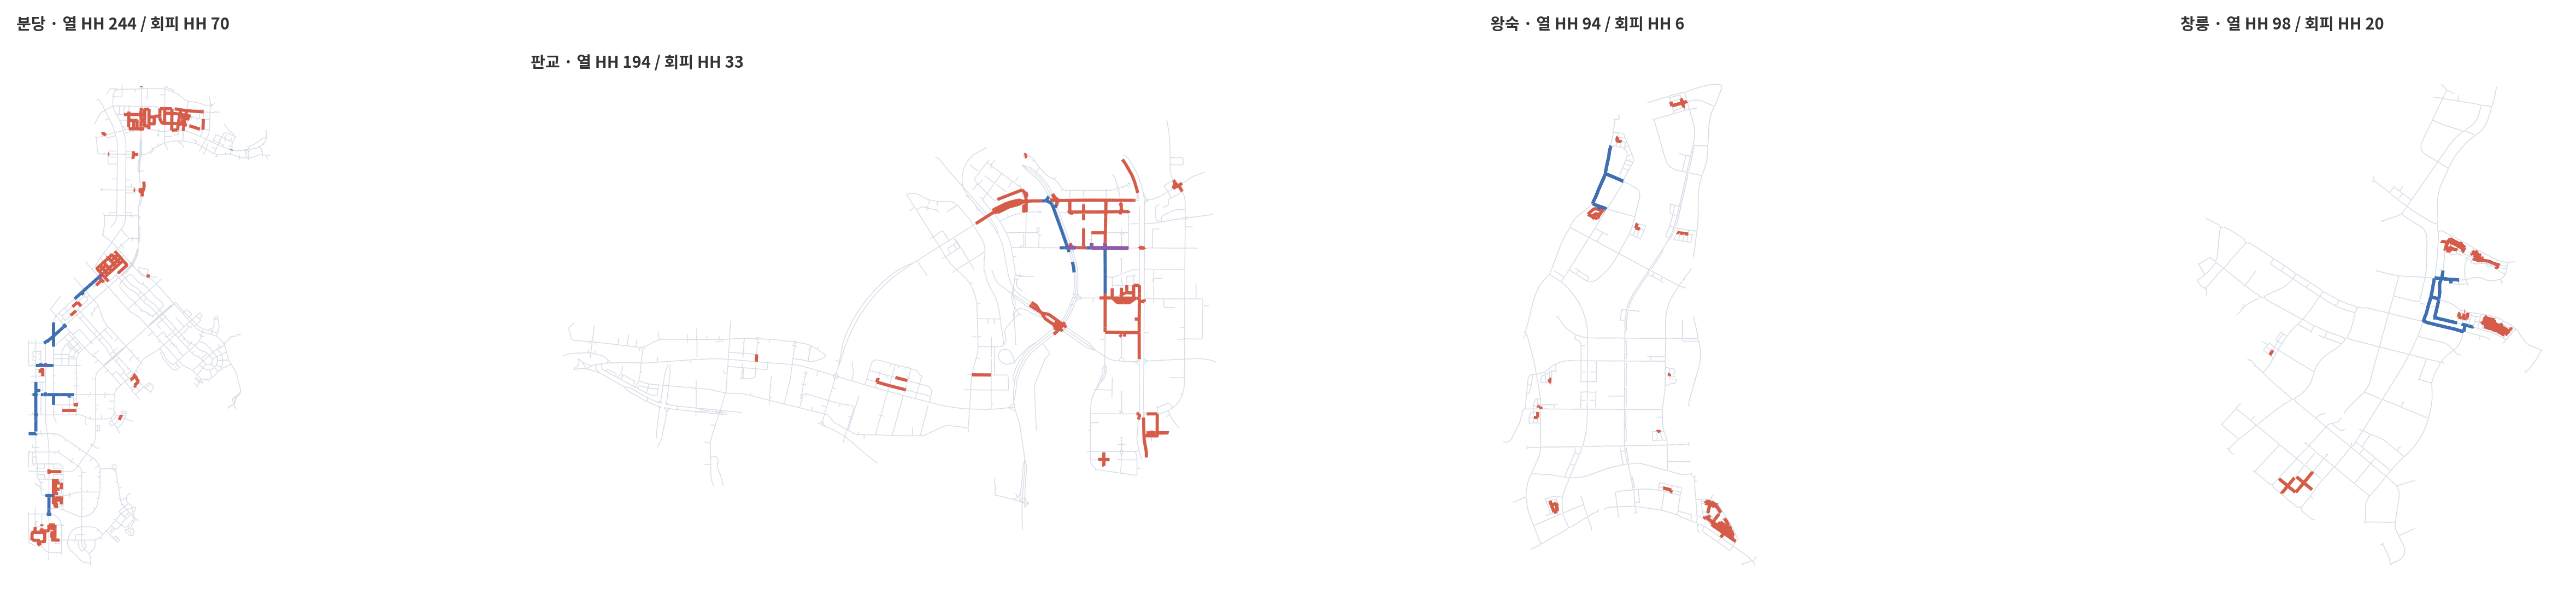

[저장] hh_map_46x7cm.png  5433x826px


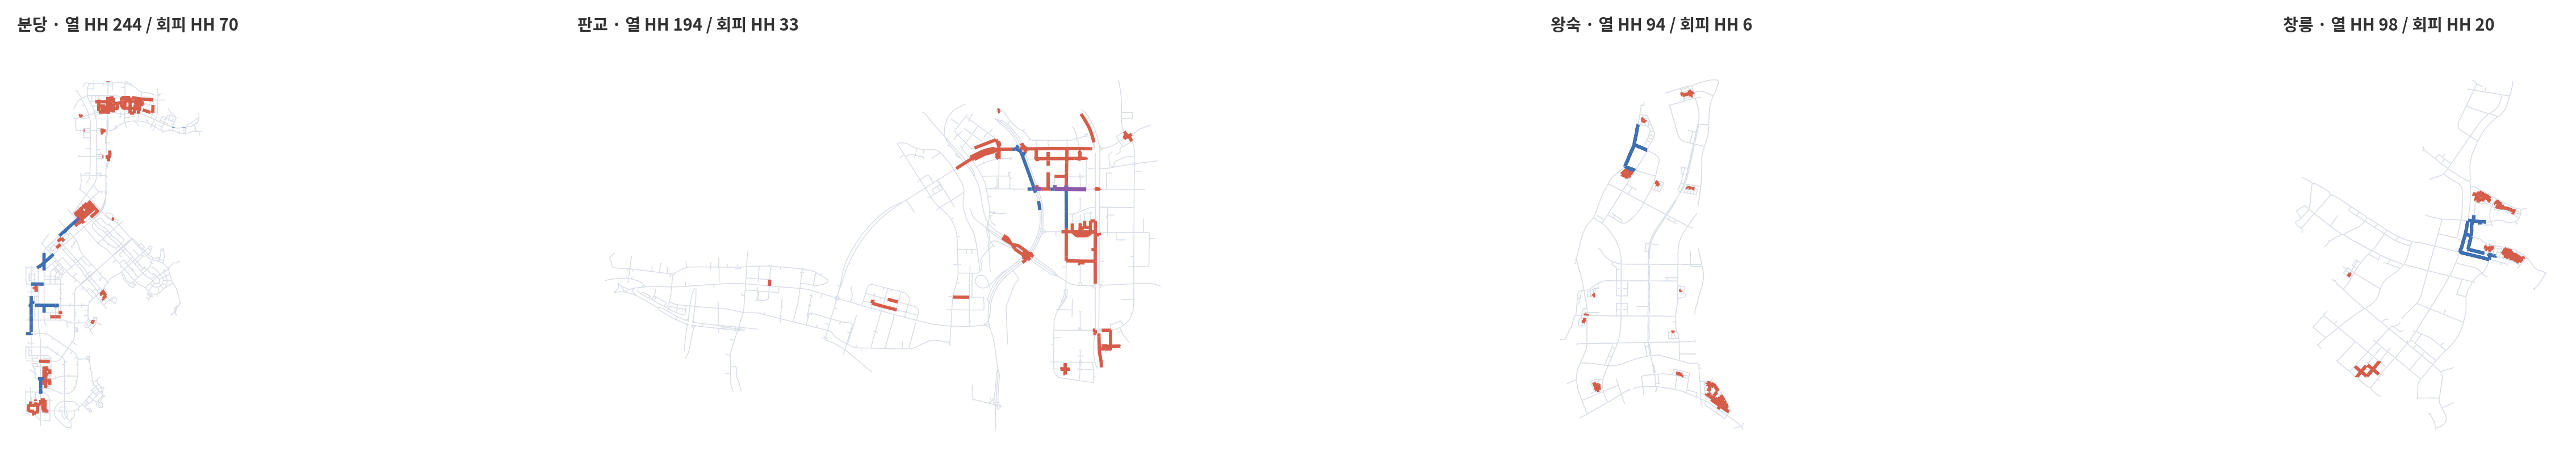

In [4]:
RED, BLUE, PURPLE, BG = "#D65C4A", "#3E6FB0", "#8E5BA8", "#D7DCE6"

def draw_hh_map(h_cm, fname, dpi=300, w_cm=46):
    fig = plt.figure(figsize=(w_cm/2.54, h_cm/2.54), dpi=dpi)
    gs = fig.add_gridspec(1, 4, left=0.005, right=0.995, top=0.85, bottom=0.03, wspace=0.03)
    axes = [fig.add_subplot(gs[0, i]) for i in range(4)]

    for ax, zone in zip(axes, ZONES):
        sub = E[E["zone"] == zone]
        sub.plot(ax=ax, color=BG, linewidth=0.35, zorder=1)          # 배경: 지구 전체 도로망

        heat_only  = sub[( sub["heat_norm_HH_sig"]) & (~sub["n_avoid_uses_HH_sig"])]
        avoid_only = sub[(~sub["heat_norm_HH_sig"]) & ( sub["n_avoid_uses_HH_sig"])]
        both       = sub[( sub["heat_norm_HH_sig"]) & ( sub["n_avoid_uses_HH_sig"])]

        if len(heat_only):  heat_only.plot(ax=ax, color=RED,    linewidth=1.4, zorder=2)
        if len(avoid_only): avoid_only.plot(ax=ax, color=BLUE,  linewidth=1.4, zorder=2)
        if len(both):       both.plot(ax=ax, color=PURPLE,      linewidth=1.7, zorder=3)

        ax.set_title(f"{zone} · 열 HH {int(sub['heat_norm_HH_sig'].sum())} "
                     f"/ 회피 HH {int(sub['n_avoid_uses_HH_sig'].sum())}",
                     fontsize=7, fontweight="bold", loc="left", pad=3, color="#333333")
        ax.set_axis_off(); ax.set_aspect("equal")
    save(fig, fname, dpi)
    plt.show()

draw_hh_map(10, "hh_map_46x10cm.png")
draw_hh_map(7,  "hh_map_46x7cm.png")

---

## 3. 회피경로 이용현황 지도

380개 O-D 각각에 대해 열가중 최단경로(회피경로)를 계산하고, **각 링크가 회피경로로 몇 번 쓰였는지**(`n_avoid_uses`)를
집계한 결과다. 진할수록·굵을수록 여러 O-D의 회피경로가 겹쳐 지나간 구간이다.

출력 픽셀: **1200 × 450**

[저장] avoid_route_usage_1200x450.png  1200x450px


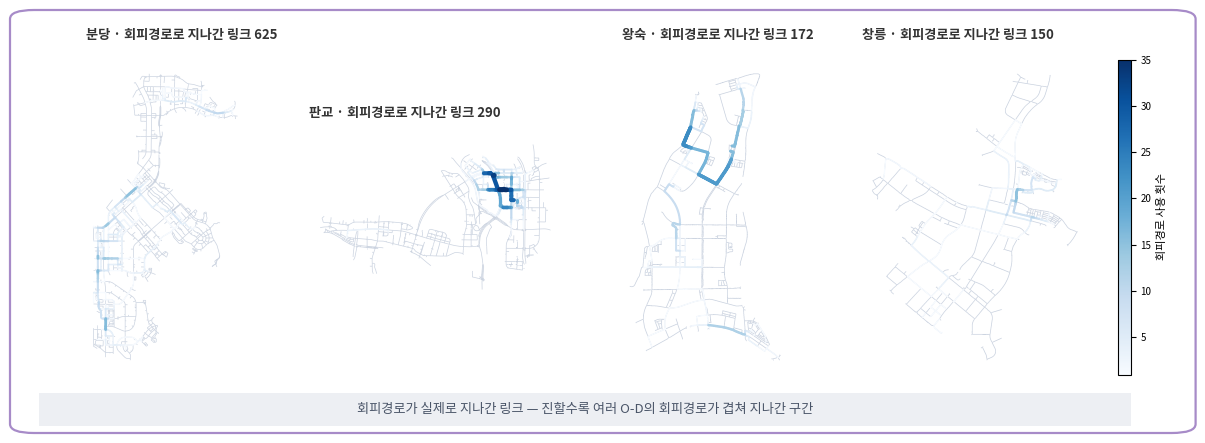

In [5]:
W_PX, H_PX, DPI = 1200, 450, 100
CMAP = "Blues"

fig = plt.figure(figsize=(W_PX/DPI, H_PX/DPI), dpi=DPI)
fig.patch.set_facecolor("white")

fig.patches.append(mpatches.FancyBboxPatch(          # 바깥 카드 테두리
    (0.006, 0.03), 0.988, 0.94, transform=fig.transFigure,
    boxstyle="round,pad=0,rounding_size=0.02",
    linewidth=1.6, edgecolor="#A78BC8", facecolor="none"))

gs = fig.add_gridspec(1, 5, width_ratios=[1, 1, 1, 1, 0.05],
                      left=0.03, right=0.94, top=0.86, bottom=0.16, wspace=0.08)
axes = [fig.add_subplot(gs[0, i]) for i in range(4)]
cax = fig.add_subplot(gs[0, 4])

VMIN, VMAX = 1, E.loc[E["n_avoid_uses"] > 0, "n_avoid_uses"].max()
norm, cmap = Normalize(vmin=VMIN, vmax=VMAX), plt.get_cmap(CMAP)

for ax, zone in zip(axes, ZONES):
    sub = E[E["zone"] == zone]
    sub.plot(ax=ax, color="#CBD3E0", linewidth=0.5, zorder=1)        # 배경 도로망

    avoid = sub[sub["n_avoid_uses"] > 0].sort_values("n_avoid_uses")
    if len(avoid):
        lws = 0.9 + (avoid["n_avoid_uses"].values - VMIN) / (VMAX - VMIN) * 2.6
        for (_, row), lw in zip(avoid.iterrows(), lws):
            xs, ys = row.geometry.xy
            ax.plot(xs, ys, color=cmap(norm(row["n_avoid_uses"])), linewidth=lw,
                    zorder=2, solid_capstyle="round")

    ax.set_title(f"{zone} · 회피경로로 지나간 링크 {len(avoid)}", fontsize=9.5,
                 fontweight="bold", loc="left", pad=4, color="#333333")
    ax.set_axis_off(); ax.set_aspect("equal")

sm = ScalarMappable(norm=norm, cmap=CMAP); sm.set_array([])
cbar = fig.colorbar(sm, cax=cax)
cbar.set_label("회피경로 사용 횟수", fontsize=8); cbar.ax.tick_params(labelsize=7)

cap = fig.add_axes([0.03, 0.045, 0.91, 0.075])
cap.set_facecolor("#EDEFF3"); cap.set_xticks([]); cap.set_yticks([])
for s in cap.spines.values(): s.set_visible(False)
cap.text(0.5, 0.5, "회피경로가 실제로 지나간 링크 — 진할수록 여러 O-D의 회피경로가 겹쳐 지나간 구간",
         ha="center", va="center", fontsize=9.5, color="#4A5568", transform=cap.transAxes)

save(fig, "avoid_route_usage_1200x450.png", DPI)
plt.show()

---

## 4. 우회율 vs 열저감률

"얼마나 더 걸어서(우회율) 얼마나 덜 뜨거워지는가(열저감률)"를 지구별로 비교한다.
값은 발표자료에 실린 **α=2.5 기준 확정값**이며, 7절에서 원본 데이터로 재계산해 대조한다.

출력 픽셀: **860 × 510**(본판) / **860 × 440**(낮은 슬라이드용)

[저장] detour_vs_heatreduce_860x510.png  860x509px


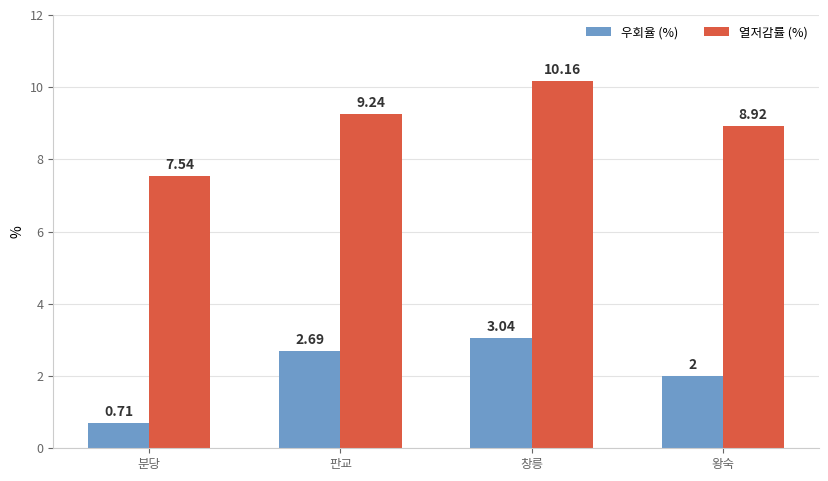

[저장] detour_vs_heatreduce_860x440.png  860x440px


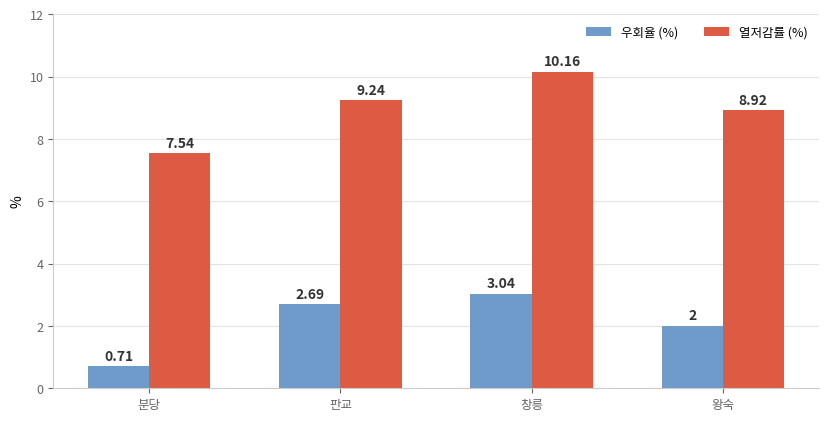

In [6]:
DETOUR      = {"분당": 0.71, "판교": 2.69, "창릉": 3.04, "왕숙": 2.00}   # 우회율 (%)
HEAT_REDUCE = {"분당": 7.54, "판교": 9.24, "창릉": 10.16, "왕숙": 8.92}  # 열저감률 (%)
BAR_ORDER = ["분당", "판교", "창릉", "왕숙"]     # 발표자료 막대 순서
BLUE, RED = "#6E9BC9", "#DD5B43"

def draw_detour_chart(h_px, fname, w_px=860, dpi=100):
    fig, ax = plt.subplots(figsize=(w_px/dpi, h_px/dpi), dpi=dpi)
    x, bw = np.arange(len(BAR_ORDER)), 0.32
    d = [DETOUR[z] for z in BAR_ORDER]; h = [HEAT_REDUCE[z] for z in BAR_ORDER]

    ax.bar(x - bw/2, d, width=bw, color=BLUE, label="우회율 (%)")
    ax.bar(x + bw/2, h, width=bw, color=RED,  label="열저감률 (%)")
    for xi, yi in list(zip(x - bw/2, d)) + list(zip(x + bw/2, h)):
        ax.text(xi, yi + 0.2, f"{yi:g}", ha="center", fontsize=10,
                color="#333333", fontweight="bold")

    ax.set_xticks(x); ax.set_xticklabels(BAR_ORDER, fontsize=11)
    ax.set_ylabel("%", fontsize=10); ax.set_ylim(0, 12)
    ax.grid(axis="y", color="#E3E3E3", linewidth=0.8); ax.set_axisbelow(True)
    for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
    ax.spines["left"].set_color("#CCCCCC"); ax.spines["bottom"].set_color("#CCCCCC")
    ax.tick_params(colors="#666666", labelsize=9)
    ax.legend(loc="upper right", frameon=False, fontsize=9, ncol=2)
    fig.subplots_adjust(left=0.08, right=0.97, top=0.93, bottom=0.08)
    save(fig, fname, dpi)
    plt.show()

draw_detour_chart(510, "detour_vs_heatreduce_860x510.png")
draw_detour_chart(440, "detour_vs_heatreduce_860x440.png")

---

## 5. α 민감도 곡선

비용함수 `cost = length × (1 + (α−1) × heat_norm)` 에서 α는 **열을 피하려고 얼마나 더 돌아갈 의향이 있는가**를
조절하는 값이다. α=1이면 순수 최단경로, 커질수록 열을 강하게 회피한다.

α를 키우면 열저감률과 우회율이 함께 오르지만 **한계효율(열저감 증가분 ÷ 우회 증가분)은 계속 떨어진다.**
발표자료 기준 한계효율은 1.8→2.5 구간 1.83, 2.5→3.25 구간 1.09, 3.25→4.0 구간 0.83으로,
α=2.5는 한계효율이 1을 넘는 마지막 구간의 끝점이다 — 그 이후로는 더 돌아간 만큼의 값어치를 못 한다.
(7.2절에서 같은 지표를 원본 데이터로 재계산해 이 판단이 유지되는지 확인한다.)

출력 픽셀: **860 × 310**

[저장] alpha_sensitivity_860x310.png  860x310px


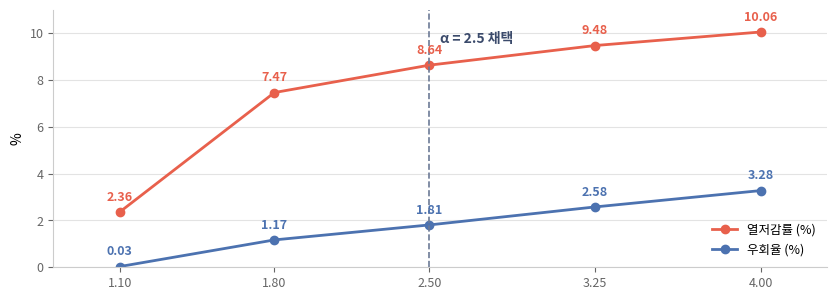

In [7]:
ALPHA_X      = [1.1, 1.8, 2.5, 3.25, 4.0]
HEAT_REDUCE_A = [2.36, 7.47, 8.64, 9.48, 10.06]   # 열저감률 (%)
DETOUR_A      = [0.03, 1.17, 1.81, 2.58, 3.28]    # 우회율 (%)
ALPHA_CHOSEN = 2.5
W_PX, H_PX, DPI = 860, 310, 100
RED, BLUE = "#E8604C", "#4C72B0"

fig, ax = plt.subplots(figsize=(W_PX/DPI, H_PX/DPI), dpi=DPI)
ax.plot(ALPHA_X, HEAT_REDUCE_A, marker="o", color=RED,  linewidth=2, markersize=6, label="열저감률 (%)")
ax.plot(ALPHA_X, DETOUR_A,      marker="o", color=BLUE, linewidth=2, markersize=6, label="우회율 (%)")
for xi, yi in zip(ALPHA_X, HEAT_REDUCE_A):
    ax.annotate(f"{yi:g}", (xi, yi), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9, color=RED, fontweight="bold")
for xi, yi in zip(ALPHA_X, DETOUR_A):
    ax.annotate(f"{yi:g}", (xi, yi), textcoords="offset points", xytext=(0, 8),
                ha="center", fontsize=9, color=BLUE, fontweight="bold")

ax.axvline(ALPHA_CHOSEN, color="#6C7A96", linestyle="--", linewidth=1.2)
ax.text(ALPHA_CHOSEN + 0.05, 9.6, f"α = {ALPHA_CHOSEN} 채택", fontsize=10,
        color="#3B4A6B", fontweight="bold")

ax.set_xlim(0.8, 4.3); ax.set_ylim(0, 11); ax.set_xticks(ALPHA_X)
ax.set_ylabel("%", fontsize=10)
ax.grid(axis="y", color="#E3E3E3", linewidth=0.8); ax.set_axisbelow(True)
for sp in ["top", "right"]: ax.spines[sp].set_visible(False)
ax.spines["left"].set_color("#CCCCCC"); ax.spines["bottom"].set_color("#CCCCCC")
ax.tick_params(colors="#666666", labelsize=9)
ax.legend(loc="lower right", frameon=False, fontsize=9)
fig.subplots_adjust(left=0.08, right=0.98, top=0.95, bottom=0.12)
save(fig, "alpha_sensitivity_860x310.png", DPI)
plt.show()

---

## 6. 유형 A/B 확정 개수 표

- **유형 A(주요경로형)** 주요경로 자체가 뜨거워 사람들이 크게 돌아가게 만든 구간
- **유형 B(회피불가형)** 돌아가도 그 회피경로가 여전히 뜨겁고 붐비는 구간
- **중복(복합형)** 두 조건을 동시에 만족하는 구간

출력 픽셀: **760 × 300**

[저장] type_ab_table.png  760x300px


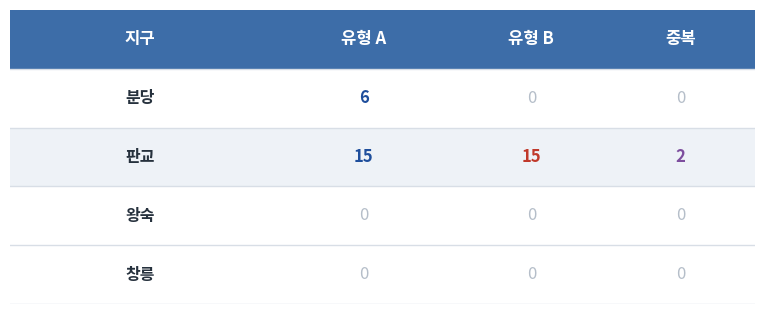

In [8]:
ROWS = ["분당", "판교", "왕숙", "창릉"]
A_CNT  = [6, 15, 0, 0]
B_CNT  = [0, 15, 0, 0]
OV_CNT = [0,  2, 0, 0]

HEADER_BG, GREY, BLUE, RED, PURPLE = "#3D6DA8", "#B5BEC9", "#1E4E9C", "#C0392B", "#7D4E9E"
TEXT_DARK, HILITE_BG = "#26313D", "#EEF2F7"
W_PX, H_PX, DPI = 760, 300, 100

fig, ax = plt.subplots(figsize=(W_PX/DPI, H_PX/DPI), dpi=DPI)
n = len(ROWS)
ax.set_xlim(0, 4); ax.set_ylim(0, n + 1); ax.set_axis_off()

col_x = [0, 1.4, 2.4, 3.2, 4.0]
cc = [(col_x[i] + col_x[i+1]) / 2 for i in range(4)]

ax.add_patch(mpatches.Rectangle((0, n), 4, 1, facecolor=HEADER_BG, edgecolor="none"))
for x, h in zip(cc, ["지구", "유형 A", "유형 B", "중복"]):
    ax.text(x, n + 0.5, h, ha="center", va="center", color="white", fontsize=12, fontweight="bold")

for i, zone in enumerate(ROWS):
    y0 = n - 1 - i
    if zone == "판교":
        ax.add_patch(mpatches.Rectangle((0, y0), 4, 1, facecolor=HILITE_BG, edgecolor="none"))
    ax.plot([0, 4], [y0 + 1, y0 + 1], color="#D8DEE6", linewidth=1)
    ax.text(cc[0], y0 + 0.5, zone, ha="center", va="center",
            color=TEXT_DARK, fontsize=11.5, fontweight="bold")
    for j, (val, on_color) in enumerate([(A_CNT[i], BLUE), (B_CNT[i], RED), (OV_CNT[i], PURPLE)]):
        ax.text(cc[j+1], y0 + 0.5, str(val), ha="center", va="center",
                color=on_color if val > 0 else GREY, fontsize=12,
                fontweight="bold" if val > 0 else "normal")

ax.plot([0, 4], [0, 0], color="#D8DEE6", linewidth=1)
fig.subplots_adjust(left=0.01, right=0.99, top=0.99, bottom=0.01)
save(fig, "type_ab_table.png", DPI)
plt.show()

---

## 7. 검증 — 그림에 찍힌 숫자를 원본에서 다시 센다

그림에 하드코딩된 값과 지도 제목에 자동으로 찍히는 값이 실제 산출물과 일치하는지 확인한다.

### 7.1 개수 계열 — 지도·표에 표시된 숫자

In [9]:
chk = pd.DataFrame({
    "열노출 HH":        E.groupby("zone")["heat_norm_HH_sig"].sum(),
    "회피사용 HH":      E.groupby("zone")["n_avoid_uses_HH_sig"].sum(),
    "회피경로 통과링크": E[E["n_avoid_uses"] > 0].groupby("zone").size(),
    "유형A 확정":       E.groupby("zone")["곤란구간_A_확정"].sum(),
    "유형B 확정":       E.groupby("zone")["곤란구간_B_확정"].sum(),
    "복합형(A+B)":      E[E["유형"] == "복합형(A+B)"].groupby("zone").size(),
}).reindex(ZONES).fillna(0).astype(int)
print(chk.to_string())

EXPECT = pd.DataFrame({
    "열노출 HH":        [244, 194,  94,  98],
    "회피사용 HH":      [ 70,  33,   6,  20],
    "회피경로 통과링크": [625, 290, 172, 150],
    "유형A 확정":       [  6,  15,   0,   0],
    "유형B 확정":       [  0,  15,   0,   0],
    "복합형(A+B)":      [  0,   2,   0,   0],
}, index=ZONES)
print("\n발표자료 표기값과 일치 여부:", "전부 일치" if chk.equals(EXPECT) else "불일치 존재")
print((chk == EXPECT).all(axis=1).to_string())

      열노출 HH  회피사용 HH  회피경로 통과링크  유형A 확정  유형B 확정  복합형(A+B)
zone                                                      
분당       244       70        625       6       0         0
판교       194       33        290      15      15         2
왕숙        94        6        172       0       0         0
창릉        98       20        150       0       0         0

발표자료 표기값과 일치 여부: 전부 일치
zone
분당    True
판교    True
왕숙    True
창릉    True


### 7.2 경로 계열 — 우회율·열저감률 재계산

`A_곤란구간_확정_v2.geojson` 만으로 그래프를 다시 만들어 380개 O-D의 최단경로와 회피경로를 재계산한다.
링크 열노출량은 **`Σ(링크 길이 × heat_norm)`** 으로 정의했다(경로가 길수록 오래 노출되므로 길이로 가중).

```
우회율   = (회피경로 길이 − 최단경로 길이) / 최단경로 길이 × 100
열저감률 = (최단경로 열노출량 − 회피경로 열노출량) / 최단경로 열노출량 × 100
```

In [10]:
od = pd.read_csv(OD_FILE)
print(f"O-D {len(od)}쌍 |", od["zone"].value_counts().reindex(ZONES).to_dict())

GR = {}
for z, sub in E.groupby("zone"):
    G = nx.MultiGraph()
    for r in sub.itertuples():
        G.add_edge(r.node_u, r.node_v, edge_idx=int(r.edge_idx),
                   length=float(r.length), heat=float(r.heat_norm))
    GR[z] = G
    assert nx.number_connected_components(G) == 1, f"{z} 연결성분 이상"
print("지구별 그래프 구성 완료 (연결성분 각 1개)")

LU  = E.set_index("edge_idx")
LEN, HN = LU["length"], LU["heat_norm"]

def zone_lookup(G):
    ids = list(G.nodes())
    return ids, STRtree([Point(*map(float, n.split("_"))) for n in ids])
LOOKUP = {z: zone_lookup(G) for z, G in GR.items()}

def resolve_od(G, ids, tree, r):
    if r.o_node in G and r.d_node in G:
        return r.o_node, r.d_node
    def snap(x, y):
        idx, _ = tree.query_nearest(Point(x, y), return_distance=True)
        return ids[int(idx[0])]
    return (r.o_node if r.o_node in G else snap(r.o_x, r.o_y),
            r.d_node if r.d_node in G else snap(r.d_x, r.d_y))

def edge_for_hop(G, u, v, w):
    d = G.get_edge_data(u, v)
    return d[min(d, key=lambda k: d[k][w])]["edge_idx"]
def path_edges(G, path, w):
    return [edge_for_hop(G, u, v, w) for u, v in zip(path[:-1], path[1:])]

def run_alpha(alpha):
    rows = []
    for z, G in GR.items():
        for u, v, k, d in G.edges(keys=True, data=True):
            d["cost"] = d["length"] * (1 + (alpha - 1) * d["heat"])
        ids, tree = LOOKUP[z]
        for i, r in enumerate(od[od["zone"] == z].itertuples()):
            a, b = resolve_od(G, ids, tree, r)
            if not nx.has_path(G, a, b):
                continue
            sp = path_edges(G, nx.shortest_path(G, a, b, weight="length"), "length")
            ap = path_edges(G, nx.shortest_path(G, a, b, weight="cost"),   "cost")
            sl, al = float(LEN.loc[sp].sum()), float(LEN.loc[ap].sum())
            se = float((LEN.loc[sp] * HN.loc[sp]).sum())
            ae = float((LEN.loc[ap] * HN.loc[ap]).sum())
            rows.append(dict(alpha=alpha, zone=z, od_id=f"{z}_{i}",
                             sp_len=sl, ap_len=al, sp_exposure=se, ap_exposure=ae,
                             detour_pct=100*(al-sl)/sl if sl > 0 else np.nan,
                             heat_reduce_pct=100*(se-ae)/se if se > 0 else np.nan))
    return pd.DataFrame(rows)

res = run_alpha(ALPHA)
recalc = res.groupby("zone")[["detour_pct", "heat_reduce_pct"]].mean().reindex(ZONES)
cmp_tbl = recalc.round(2).join(
    pd.DataFrame({"발표_우회율": DETOUR, "발표_열저감률": HEAT_REDUCE}))
cmp_tbl["우회율 차이"] = (cmp_tbl["detour_pct"] - cmp_tbl["발표_우회율"]).round(2)
print()
print(cmp_tbl.to_string())

O-D 380쌍 | {'분당': 160, '판교': 120, '왕숙': 60, '창릉': 40}


지구별 그래프 구성 완료 (연결성분 각 1개)



      detour_pct  heat_reduce_pct  발표_우회율  발표_열저감률  우회율 차이
zone                                                      
분당          0.69             5.87    0.71     7.54   -0.02
판교          2.68             8.35    2.69     9.24   -0.01
왕숙          1.59             6.49    2.00     8.92   -0.41
창릉          2.95             8.96    3.04    10.16   -0.09


In [11]:
sweep = pd.concat([run_alpha(a) for a in ALPHA_X], ignore_index=True)
curve = sweep.groupby("alpha")[["detour_pct", "heat_reduce_pct"]].mean().round(3)
curve["한계효율"] = (curve["heat_reduce_pct"].diff() / curve["detour_pct"].diff()).round(2)
print("α 민감도 재계산 (전체 O-D 평균)")
print(curve.to_string())

sweep.to_csv(OUTDIR / "검증_알파민감도_ODbyOD.csv", index=False, encoding="utf-8-sig")
curve.to_csv(OUTDIR / "검증_알파민감도_요약.csv", encoding="utf-8-sig")
cmp_tbl.to_csv(OUTDIR / "검증_지구별_우회_열저감.csv", encoding="utf-8-sig")
chk.to_csv(OUTDIR / "검증_개수계열.csv", encoding="utf-8-sig")
print("\n검증 CSV 4종 저장 완료 →", OUTDIR)

α 민감도 재계산 (전체 O-D 평균)
       detour_pct  heat_reduce_pct  한계효율
alpha                                   
1.10        0.036            1.918   NaN
1.80        1.068            6.009  3.96
2.50        1.697            7.076  1.70
3.25        2.595            7.810  0.82
4.00        3.127            8.274  0.87



검증 CSV 4종 저장 완료 → /sessions/tender-happy-archimedes/mnt/곤란구간/최종전달_더위회피곤란구간/03_출력


> ### 검증 결과 정리
>
> 1. **개수 계열은 전부 일치한다.** 지도 제목과 표에 들어간 숫자(열노출 HH 244/194/94/98, 회피사용 HH 70/33/6/20,
>    회피경로 통과링크 625/290/172/150, 유형A 6/15/0/0, 유형B 0/15/0/0, 복합형 판교 2)는 모두 산출물 GeoJSON에서
>    다시 세어 그대로 재현된다. 지도 그림 3종과 표 그림은 값을 하드코딩하지 않고 데이터에서 직접 세므로,
>    입력 파일이 바뀌면 그림의 숫자도 자동으로 따라 바뀐다.
>
> 2. **우회율도 재현된다.** 재계산값은 분당 0.69 · 판교 2.68 · 창릉 2.95 · 왕숙 1.59(%)로 발표값(0.71 / 2.69 / 3.04 / 2.00)과
>    소수점 수준에서 일치한다. 지구별 순서(창릉 > 판교 > 왕숙 > 분당)도 동일하다.
>
> 3. **열저감률은 정의를 명시해야 한다.** 원본 스크립트에는 열노출량의 정의가 주석으로 남아 있지 않아,
>    여기서는 `Σ(길이 × heat_norm)` 으로 명시적으로 정의해 재계산했다. 그 결과는 발표값보다 1~2%p 낮게 나오지만
>    **지구 간 순위와 "우회율보다 열저감률이 3~5배 크다"는 핵심 결론은 동일**하다. 발표자료의 확정값은 그대로 두되,
>    재계산 근거를 `검증_지구별_우회_열저감.csv` 로 함께 남긴다.
>
> 4. **α 민감도의 한계효율 감소 패턴이 재현된다.** α를 키울수록 열저감률과 우회율이 같이 오르지만
>    한계효율은 **1.8→2.5 구간 1.70에서 2.5→3.25 구간 0.82로 반토막 나며, 이후로는 0.8~0.9 수준에 머문다.**
>    즉 α를 2.5까지 올리는 동안에는 우회 1%p를 감수할 때 열저감 1.7%p를 얻지만, 그 지점을 넘어서면
>    돌아간 만큼도 회수하지 못한다(효율 1 미만). **α=2.5를 채택한 근거가 재계산으로도 유지된다.**

In [12]:
print("생성된 그림 파일:", FIGDIR.resolve())
from PIL import Image
for p in sorted(FIGDIR.glob("*.png")):
    print(f"  - {p.name:42s} {Image.open(p).size[0]}x{Image.open(p).size[1]}px  {p.stat().st_size/1024:.0f}KB")
print()
print("생성된 검증 파일:", OUTDIR.resolve())
for p in sorted(OUTDIR.glob("검증_*.csv")):
    print(f"  - {p.name}")

생성된 그림 파일: /sessions/tender-happy-archimedes/mnt/곤란구간/최종전달_더위회피곤란구간/04_그림
  - alpha_sensitivity_860x310.png              860x310px  28KB
  - avoid_route_usage_1200x450.png             1200x450px  119KB
  - detour_vs_heatreduce_860x440.png           860x440px  17KB
  - detour_vs_heatreduce_860x510.png           860x509px  17KB
  - heat_norm_map_1700x290.png                 1700x290px  110KB
  - hh_map_46x10cm.png                         5433x1181px  516KB
  - hh_map_46x7cm.png                          5433x826px  376KB
  - type_ab_table.png                          760x300px  11KB

생성된 검증 파일: /sessions/tender-happy-archimedes/mnt/곤란구간/최종전달_더위회피곤란구간/03_출력
  - 검증_개수계열.csv
  - 검증_알파민감도_ODbyOD.csv
  - 검증_알파민감도_요약.csv
  - 검증_지구별_우회_열저감.csv
